In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.interpolate import griddata
from matplotlib.colors import LogNorm
from TDECalculator import TDECalculator

plt.style.use("plot_style.mplstyle")
plt.rc('text', usetex=True)

## Call the TDECalculator class ##

In [4]:
# orbit denotes the type of trajectory, 'nwtn' for Newtonian and 'rel' for relativistic
# MBH is the black hole masses, in units of solar masses
# Rp is the pericenter distance, in units of G MBH
# a is the black hole spin, in units of MBH
# E is orbital energy of the star's center of mass
# Q is the Carter constant of the star's center of mass
# N is the number of steps in the time integration
calc_pro = TDECalculator('BD_40MJ_z0.0300_AGE10Gyr', orbit='rel', MBH=1e6, Rp=5.805, a=0.2, E=1.0, Q=0.0, N=1000)        # prograde trajectory
#calc_retro = TDECalculator('BD_40MJ_z0.0010_AGE10Gyr', orbit='rel', MBH=1e6, Rp=6.0, a=-0.2, E=1.0, Q=0.0, N=3500)     # retrograde trajectory
#calc_sch = TDECalculator('BD_40MJ_z0.0010_AGE10Gyr', orbit='rel', MBH=1e6, Rp=6.0, a=0.0, E=1.0, Q=0.0, N=3500)         # schwartzschild trajectory
#calc_nwtn = TDECalculator('BD_40MJ_z0.0010_AGE10Gyr', orbit='nwtn', MBH=1e6, Rp=6.0, a=0.0, E=1.0, Q=0.0, N=3500)      # newtonian trajectory

In [5]:
print("Mstar =", calc_pro.Mstar)
print("Rstar =", calc_pro.Rstar)
print("Rtidal =", calc_pro.Rtidal)
print("Rp =", calc_pro.Rp)
print("beta =", calc_pro.Rtidal / calc_pro.Rp)

print("U =", calc_pro.U)
print("gamma =", calc_pro.gamma)

threshold = calc_pro.gamma * (
    calc_pro.U * calc_pro.mass_ratio**2 / calc_pro.Rstar
)

print("threshold =", threshold)
print("max TidalEnergy =", np.max(calc_pro.TidalEnergy))
print(
    "energy / threshold =",
    np.max(calc_pro.TidalEnergy) / threshold
)

Mstar = 0.03819396160205565
Rstar = 0.03909939851002627
Rtidal = 11.61016808882579
Rp = 5.805
beta = 2.000028955870076
U = 0.8213864645759327
gamma = 0.3495255931458709
threshold = 1.0711390715331546e-14
max TidalEnergy = 4.857418866724258e-13
energy / threshold = 45.34816249183856


## Plot the deformed star's equator density ##

In [3]:
def density_plots(calc):
    # Use the “equator_sample” method to get POS and dMass.
    # Here we use equator_sample to get an equatorial slice:
    equator_sample = calc.equator_sample()
    POS    = equator_sample['POS']        # shape (n_r, 1, n_phi, 3)
    dMass  = equator_sample['dMass']      # shape (n_r, n_phi)

    # flatten x, y, and mass
    x_pos   = POS[...,0].flatten()
    y_pos   = POS[...,1].flatten()
    mass_flat = dMass.flatten()

    # define histogram bin edges
    nbins   = 300
    x_edges = np.linspace(-2, 2, nbins+1)
    y_edges = np.linspace(-3, 3, nbins+1)

    # build 2D mass histogram
    mass_hist, x_edges, y_edges = np.histogram2d(
        x_pos, y_pos,
        bins=[x_edges, y_edges],
        weights=mass_flat
    )

    # convert to surface density
    dx    = x_edges[1] - x_edges[0]
    dy    = y_edges[1] - y_edges[0]
    area  = dx*dy
    density2D = mass_hist / area
    # add tiny non‑constant offset for stable contours
    Xc, Yc = np.meshgrid(
        0.5*(x_edges[:-1]+x_edges[1:]),
        0.5*(y_edges[:-1]+y_edges[1:])
    )
    density2D += 1e-12*(Xc + Yc)

    # prepare interpolation onto a finer grid
    points = np.column_stack((Xc.flatten(), Yc.flatten()))
    values = density2D.T.flatten()
    xi     = np.linspace(Xc.min(), Xc.max(), nbins)
    yi     = np.linspace(Yc.min(), Yc.max(), nbins)
    XI, YI = np.meshgrid(xi, yi)
    dens_interp = griddata(points, values, (XI, YI), method='linear')
    # normalize for plotting
    dens_interp += dens_interp.max()*1e-8
    center_idx_x = tuple(dim // 2 for dim in XI.shape)[0]
    center_idx_y = tuple(dim // 2 for dim in YI.shape)[0]
    Sigma_c = dens_interp[center_idx_x, center_idx_y]
    dens_interp /= Sigma_c

    # — plot! —
    plt.figure(figsize=(8,8))
    levels = np.logspace(
        np.log10(dens_interp[dens_interp>0].min()),
        np.log10(dens_interp.max()),
        100
    )
    cf = plt.contourf(
        XI, YI, dens_interp,
        levels=levels,
        cmap='viridis',
        norm=LogNorm()
    )

    # arrow pointing “to BH”
    phi0 = calc.Psi_TDE if calc.orbit == "rel" else calc.Phi_TDE
    plt.arrow(-1.5, 2.25, -0.3*np.cos(phi0), -0.3*np.sin(phi0),
            linewidth=2, head_width=0.1, head_length=0.1, color='white')
    plt.text(-1.5-0.3*np.cos(phi0)+0.1,
            2.25-0.3*np.sin(phi0)+0.1,
            'to BH', color='white', fontsize=14)

    # annotate mass and β
    beta = calc.Rtidal / calc.Rp
    plt.text(1.3, 2.5,  fr'${calc.star_name[4:-4]}\,M_\odot$',
            color='white', fontsize=20)
    plt.text(-1.7, -2.5, fr'$\beta={beta:.2f}$',
            color='white', fontsize=20)

    plt.axis('scaled')
    plt.axis('off')
    plt.colorbar(cf, label='$\\rho/\\rho_c$', ticks=[1e-8, 1e-6, 1e-4, 1e-2, 1])
    plt.show()

### Prograde ###

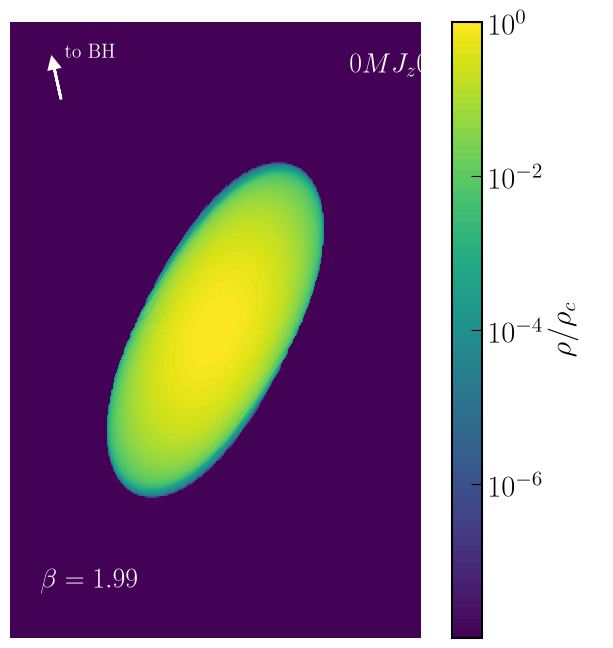

In [4]:
density_plots(calc_pro)

### Retrograde ###

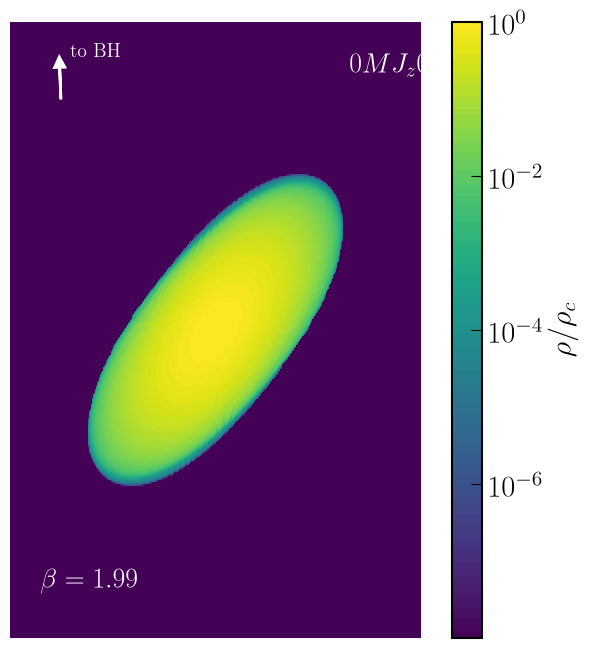

In [5]:
density_plots(calc_retro)

### Schwartzschild ###

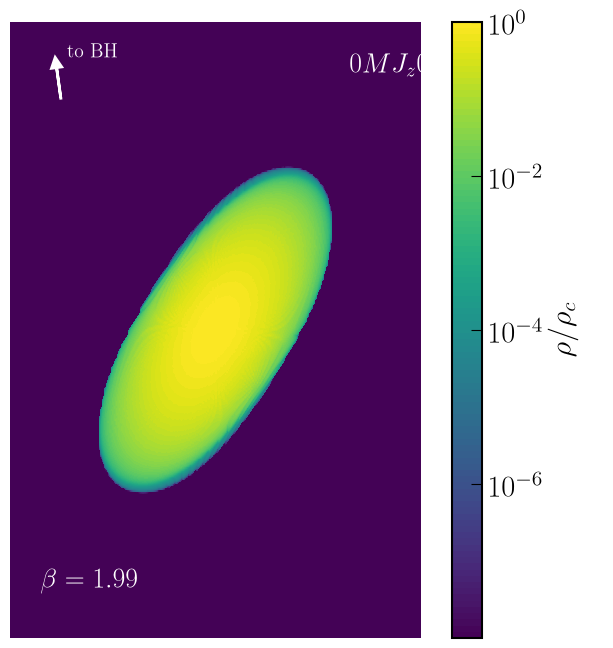

In [6]:
density_plots(calc_sch)

### Newtonian ###

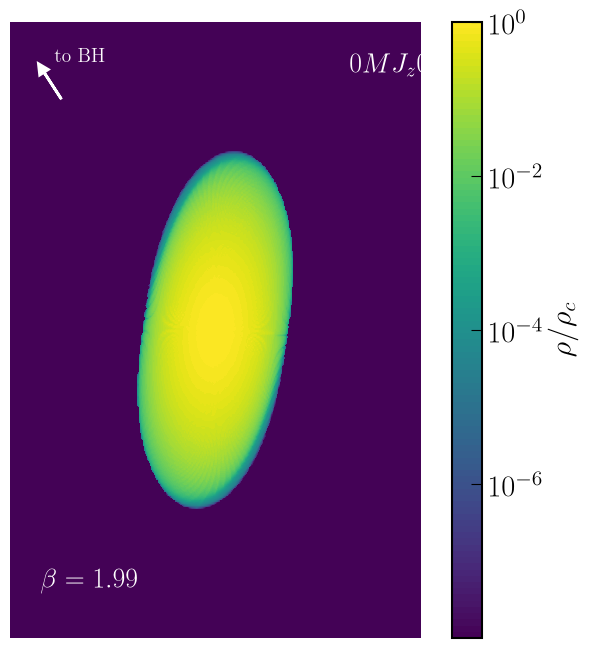

In [7]:
density_plots(calc_nwtn)

## Compute $dM/dE$ and $dM/dT$ ##

see FallbackGen_example.ipynb